<a href="https://colab.research.google.com/github/zdaibou1996-prog/Zdaibou1996-prog/blob/main/Day_4_Python_Activity_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pandas, Matplotlib and Seaborn

In [ ]:
import pandas as pd

[Dataset Soruce](https://www.kaggle.com/datasets/rajkumarpandey02/gdp-in-usd-per-capita-income-by-country)

CONTENT
<p>The figures presented here do not take into account differences in the cost of living in different countries, and the results vary greatly from one year to another based on fluctuations in the exchange rates of the country's currency. Such fluctuations change a country's ranking from one year to the next, even though they often make little or no difference to the standard of living of its population.

GDP per capita is often considered an indicator of a country's standard of living; however, this is inaccurate because GDP per capita is not a measure of personal income.

Comparisons of national income are also frequently made on the basis of purchasing power parity (PPP), to adjust for differences in the cost of living in different countries. (See List of countries by GDP (PPP) per capita.) PPP largely removes the exchange rate problem but not others; it does not reflect the value of economic output in international trade, and it also requires more estimation than GDP per capita. On the whole, PPP per capita figures are more narrowly spread than nominal GDP per capita figures.</p>

Here are some resources to learn about GDP:
#### [World Bank](https://data.worldbank.org/indicator/ny.gdp.pcap.cd?most_recent_value_desc=false)
#### [Our World in Data](https://ourworldindata.org/grapher/gdp-per-capita-worldbank)
#### [IMF](https://www.imf.org/external/datamapper/NGDPD@WEO/OEMDC/ADVEC/WEOWORLD)
#### [UN Data](https://data.un.org/Data.aspx?d=SNAAMA&f=grID%3A101%3BcurrID%3AUSD%3BpcFlag%3A1)



In [ ]:
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded)))
# Convertir les colonnes GDP en nombres propres
for col in ["IMF_Estimate", "WorldBank_Estimate", "UN_Estimate"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
df.head()

Saving GDP (nominal) per Capita.csv to GDP (nominal) per Capita (1).csv


,Unnamed: 0,Country/Territory,UN_Region,IMF_Estimate,IMF_Year,WorldBank_Estimate,WorldBank_Year,UN_Estimate,UN_Year
0,1,Monaco,Europe,0,0,234316,2021,234317,2021
1,2,Liechtenstein,Europe,0,0,157755,2020,169260,2021
2,3,Luxembourg,Europe,132372,2023,133590,2021,133745,2021
3,4,Ireland,Europe,114581,2023,100172,2021,101109,2021
4,5,Bermuda,Americas,0,0,114090,2021,112653,2021


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("GDP (nominal) per Capita.csv")
# Convertir les colonnes GDP en nombres propres
for col in ["IMF_Estimate", "WorldBank_Estimate", "UN_Estimate"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
df.head()


,Unnamed: 0,Country/Territory,UN_Region,IMF_Estimate,IMF_Year,WorldBank_Estimate,WorldBank_Year,UN_Estimate,UN_Year
0,1,Monaco,Europe,0,0,234316,2021,234317,2021
1,2,Liechtenstein,Europe,0,0,157755,2020,169260,2021
2,3,Luxembourg,Europe,132372,2023,133590,2021,133745,2021
3,4,Ireland,Europe,114581,2023,100172,2021,101109,2021
4,5,Bermuda,Americas,0,0,114090,2021,112653,2021


In [ ]:
df.groupby("UN_Region")["WorldBank_Estimate"].mean()

,WorldBank_Estimate
UN_Region,
Africa,2470.836364
Americas,18565.125000
Asia,13921.313725
Europe,45193.687500
Oceania,15113.650000
World,12235.000000


In [ ]:
avg_gdp = df["WorldBank_Estimate"].mean()
df[df["WorldBank_Estimate"] < avg_gdp][["Country/Territory", "WorldBank_Estimate"]]

,Country/Territory,WorldBank_Estimate
30,British Virgin Islands,0
45,Taiwan,0
65,Uruguay,17313
66,Barbados,17226
68,Guyana,9999
...,...,...
218,Malawi,635
219,South Sudan,1072
220,Sierra Leone,480
221,Afghanistan,369


In [ ]:
df = pd.read_csv("GDP (nominal) per Capita.csv",encoding= 'unicode_escape',  index_col=0)

## EDA (Exploratory Data Analysis)

### Use this section to explore and inspect dataset.

In [ ]:
df.head()

,Country/Territory,UN_Region,IMF_Estimate,IMF_Year,WorldBank_Estimate,WorldBank_Year,UN_Estimate,UN_Year
1,Monaco,Europe,0,0,234316,2021,234317,2021
2,Liechtenstein,Europe,0,0,157755,2020,169260,2021
3,Luxembourg,Europe,132372,2023,133590,2021,133745,2021
4,Ireland,Europe,114581,2023,100172,2021,101109,2021
5,Bermuda,Americas,0,0,114090,2021,112653,2021


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 223 entries, 1 to 223
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Country/Territory   223 non-null    object
 1   UN_Region           223 non-null    object
 2   IMF_Estimate        223 non-null    int64 
 3   IMF_Year            223 non-null    int64 
 4   WorldBank_Estimate  223 non-null    int64 
 5   WorldBank_Year      223 non-null    int64 
 6   UN_Estimate         223 non-null    int64 
 7   UN_Year             223 non-null    object
dtypes: int64(5), object(3)
memory usage: 15.7+ KB


In [ ]:
df.describe()

,IMF_Estimate,IMF_Year,WorldBank_Estimate,WorldBank_Year,UN_Estimate
count,223.000000,223.000000,223.000000,223.000000,223.000000
mean,15351.632287,1787.098655,18927.417040,1957.278027,17767.304933
std,22550.899445,650.695912,29103.564915,353.145867,28698.104167
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1406.500000,2023.000000,2273.500000,2021.000000,2039.000000
50%,5421.000000,2023.000000,6805.000000,2021.000000,6396.000000
75%,19697.000000,2023.000000,23715.000000,2021.000000,20740.000000
max,132372.000000,2023.000000,234316.000000,2021.000000,234317.000000


In [ ]:
df.shape

(223, 8)

In [ ]:
df.groupby("UN_Region")["WorldBank_Estimate"].mean()

,WorldBank_Estimate
UN_Region,
Africa,2470.836364
Americas,18565.125000
Asia,13921.313725
Europe,45193.687500
Oceania,15113.650000
World,12235.000000


In [ ]:
avg_gdp = df["WorldBank_Estimate"].mean()
df[df["WorldBank_Estimate"] < avg_gdp][["Country/Territory", "WorldBank_Estimate"]]

,Country/Territory,WorldBank_Estimate
31,British Virgin Islands,0
46,Taiwan,0
66,Uruguay,17313
67,Barbados,17226
69,Guyana,9999
...,...,...
219,Malawi,635
220,South Sudan,1072
221,Sierra Leone,480
222,Afghanistan,369


In [ ]:
df[df["IMF_Estimate"] == 0]

,Country/Territory,UN_Region,IMF_Estimate,IMF_Year,WorldBank_Estimate,WorldBank_Year,UN_Estimate,UN_Year
1,Monaco,Europe,0,0,234316,2021,234317,2021
2,Liechtenstein,Europe,0,0,157755,2020,169260,2021
5,Bermuda,Americas,0,0,114090,2021,112653,2021
9,Isle of Man,Europe,0,0,87158,2019,0,0
10,Cayman Islands,Americas,0,0,86569,2021,85250,2021
14,Channel Islands,Europe,0,0,75153,2007,0,0
15,Faroe Islands,Europe,0,0,69010,2021,0,0
19,Greenland,Americas,0,0,54571,2020,58185,2021
31,British Virgin Islands,Americas,0,0,0,0,49444,2021
37,US Virgin Islands,Americas,0,0,39552,2020,0,0


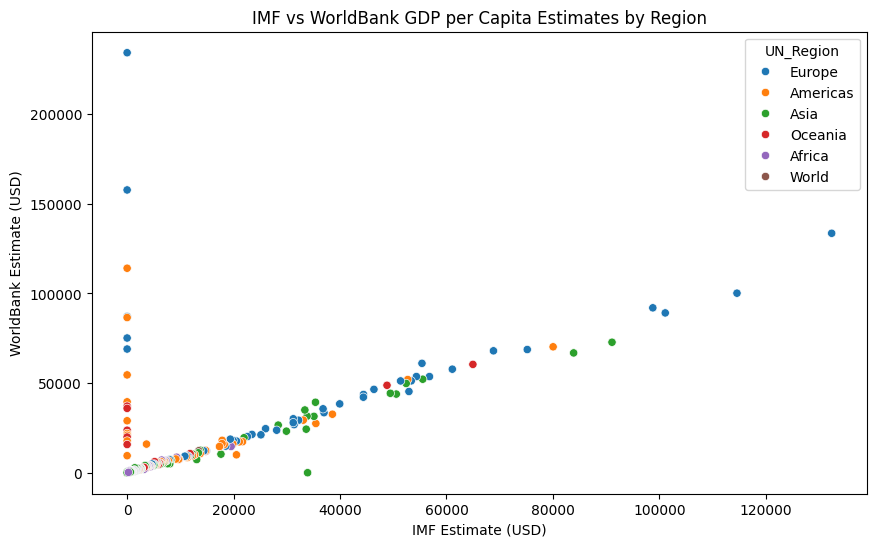

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Load the correct GDP dataset
df_gdp = pd.read_csv('GDP (nominal) per Capita.csv')
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_gdp, x="IMF_Estimate", y="WorldBank_Estimate", hue="UN_Region")
plt.title("IMF vs WorldBank GDP per Capita Estimates by Region")
plt.xlabel("IMF Estimate (USD)")
plt.ylabel("WorldBank Estimate (USD)")
plt.show()

In [ ]:
# number of countries per region

In [ ]:
df["UN_Region"] .value_counts()

,count
UN_Region,
Africa,55
Asia,51
Americas,48
Europe,48
Oceania,20
World,1


In [ ]:
print(df.columns)

Index(['Country/Territory', 'UN_Region', 'IMF_Estimate', 'IMF_Year',
       'WorldBank_Estimate', 'WorldBank_Year', 'UN_Estimate', 'UN_Year'],
      dtype='object')


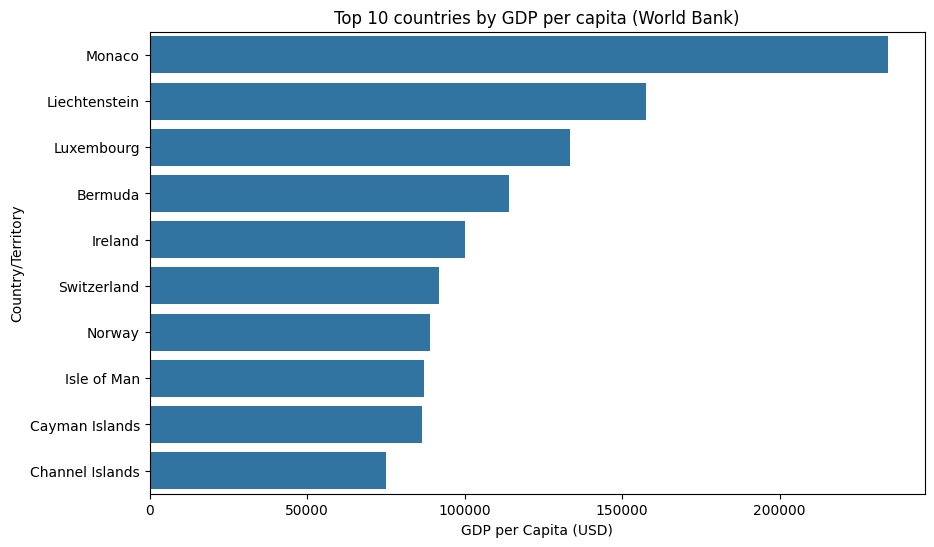

In [ ]:
top10 = df.sort_values(by='WorldBank_Estimate', ascending=False).head(10)
plt.figure(figsize=(10,6))
sns.barplot(x='WorldBank_Estimate', y='Country/Territory', data=top10)
plt.title('Top 10 countries by GDP per capita (World Bank)')
plt.xlabel('GDP per Capita (USD)')
plt.ylabel('Country/Territory')
plt.show()

In [ ]:
#What is European Union[n 1]?

In [ ]:
df[df["Country/Territory"] == "European Union[n 1]"]

,Country/Territory,UN_Region,IMF_Estimate,IMF_Year,WorldBank_Estimate,WorldBank_Year,UN_Estimate,UN_Year
36,European Union[n 1],Europe,39940,2023,38411,2021,31875,2021


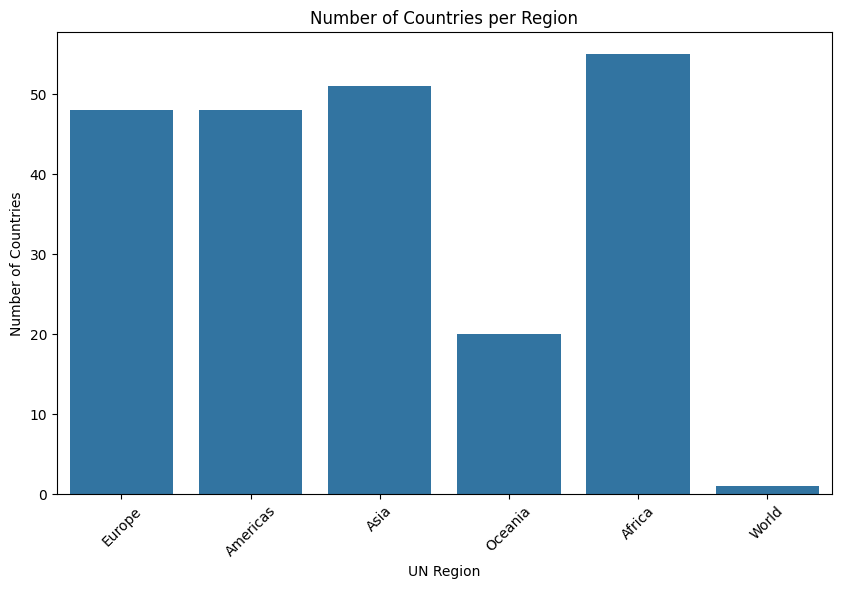

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(x="UN_Region", data=df)
plt.title("Number of Countries per Region")
plt.xlabel("UN Region")
plt.ylabel("Number of Countries")
plt.xticks(rotation=45)
plt.show()

In [ ]:
# Countries in Europe below avarege

In [ ]:
europe = df[df["UN_Region"] == "Europe"]
avg_europe = europe["WorldBank_Estimate"].mean()
print("Moyenne Europe :", avg_europe)
europe[europe["WorldBank_Estimate"] < avg_europe][["Country/Territory", "WorldBank_Estimate"]]

Moyenne Europe : 45193.6875


,Country/Territory,WorldBank_Estimate
34,France,43659
35,Andorra,42137
36,European Union[n 1],38411
40,Malta,33487
41,Italy,35658
51,Slovenia,29291
52,Czech Republic,26821
53,Spain,30104
54,Estonia,27944
57,Lithuania,23723


In [ ]:
## Which countries in Europe has higher GDP than UK?

In [ ]:
europe = df[df["UN_Region"] == "Europe"]
uk_gdp = europe[europe["Country/Territory"] == "United Kingdom"]["WorldBank_Estimate"].values[0]
print("UK GDP :", uk_gdp)
europe[europe["WorldBank_Estimate"] > uk_gdp][["Country/Territory", "WorldBank_Estimate"]].sort_values(by="WorldBank_Estimate", ascending=False)

UK GDP : 46510


,Country/Territory,WorldBank_Estimate
1,Monaco,234316
2,Liechtenstein,157755
3,Luxembourg,133590
4,Ireland,100172
7,Switzerland,91992
6,Norway,89154
9,Isle of Man,87158
14,Channel Islands,75153
15,Faroe Islands,69010
13,Iceland,68728


## groupby()

[Learn more about groupby](https://www.geeksforgeeks.org/pandas-groupby/)

In [ ]:
df.groupby("UN_Region")["WorldBank_Estimate"].mean().sort_values(ascending=False)

,WorldBank_Estimate
UN_Region,
Europe,45193.687500
Americas,18565.125000
Oceania,15113.650000
Asia,13921.313725
World,12235.000000
Africa,2470.836364


## Which countries below average by IMF world estimate?

In [ ]:
avg_imf = df["IMF_Estimate"].mean()
df[df["IMF_Estimate"] < avg_imf][["Country/Territory", "IMF_Estimate"]]



,Country/Territory,IMF_Estimate
1,Monaco,0
2,Liechtenstein,0
5,Bermuda,0
9,Isle of Man,0
10,Cayman Islands,0
...,...,...
219,Malawi,496
220,South Sudan,467
221,Sierra Leone,415
222,Afghanistan,611


### IMF estimate 0 values

In [ ]:
df[df["IMF_Estimate"] == 0][["Country/Territory", "UN_Region", "IMF_Estimate"]]

,Country/Territory,UN_Region,IMF_Estimate
1,Monaco,Europe,0
2,Liechtenstein,Europe,0
5,Bermuda,Americas,0
9,Isle of Man,Europe,0
10,Cayman Islands,Americas,0
14,Channel Islands,Europe,0
15,Faroe Islands,Europe,0
19,Greenland,Americas,0
31,British Virgin Islands,Americas,0
37,US Virgin Islands,Americas,0


## Which country has highest UN Estimate?

In [ ]:
df[df["UN_Estimate"] == df["UN_Estimate"].max()][["Country/Territory", "UN_Estimate"]]

,Country/Territory,UN_Estimate
1,Monaco,234317


## Which country has highest Worlbank Estimate?

In [ ]:
df[df["WorldBank_Estimate"] == df["WorldBank_Estimate"].max()][["Country/Territory", "WorldBank_Estimate"]]

,Country/Territory,WorldBank_Estimate
1,Monaco,234316


## Which country has highest IMF Estimate?

In [ ]:
df[df["IMF_Estimate"] == df["IMF_Estimate"].max()][["Country/Territory", "IMF_Estimate"]]

,Country/Territory,IMF_Estimate
3,Luxembourg,132372


## Filling 0 Values by average

In [ ]:
import numpy as np

In [ ]:
# replace 0 with null values

In [ ]:
df["IMF_Estimate"] = df["IMF_Estimate"].replace(0, np.nan)

In [ ]:
# Calculate the average of 'Worldbank_Estimate' and 'UN_Estimate' columns


In [ ]:
df["avg_worldbank_un"] = df[["WorldBank_Estimate", "UN_Estimate"]].mean(axis=1)

In [ ]:
# Fill the null values in 'imf' column with the calculated average


In [ ]:
df["IMF_Estimate"] = df["IMF_Estimate"].fillna(df["avg_worldbank_un"])
df.head()

,Country/Territory,UN_Region,IMF_Estimate,IMF_Year,WorldBank_Estimate,WorldBank_Year,UN_Estimate,UN_Year,avg_worldbank_un
1,Monaco,Europe,234316.5,0,234316,2021,234317,2021,234316.5
2,Liechtenstein,Europe,163507.5,0,157755,2020,169260,2021,163507.5
3,Luxembourg,Europe,132372.0,2023,133590,2021,133745,2021,133667.5
4,Ireland,Europe,114581.0,2023,100172,2021,101109,2021,100640.5
5,Bermuda,Americas,113371.5,0,114090,2021,112653,2021,113371.5


In [ ]:
# Drop the temporary 'avg_worldbank_un' column if not needed


In [ ]:
df.drop(columns=["avg_worldbank_un"], inplace=True)
df.head()

,Country/Territory,UN_Region,IMF_Estimate,IMF_Year,WorldBank_Estimate,WorldBank_Year,UN_Estimate,UN_Year
1,Monaco,Europe,234316.5,0,234316,2021,234317,2021
2,Liechtenstein,Europe,163507.5,0,157755,2020,169260,2021
3,Luxembourg,Europe,132372.0,2023,133590,2021,133745,2021
4,Ireland,Europe,114581.0,2023,100172,2021,101109,2021
5,Bermuda,Americas,113371.5,0,114090,2021,112653,2021


[Visit this link to learn more about ffill](https://www.w3schools.com/python/pandas/ref_df_ffill.asp)

[Visit this link to learn more about bfill](https://www.w3schools.com/python/pandas/ref_df_bfill.asp)

## Checking Missing Values

In [ ]:
df.isnull().sum()

,0
Country/Territory,0
UN_Region,0
IMF_Estimate,0
IMF_Year,0
WorldBank_Estimate,0
WorldBank_Year,0
UN_Estimate,0
UN_Year,0


In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df[df.isnull().any(axis=1)]

,Country/Territory,UN_Region,IMF_Estimate,IMF_Year,WorldBank_Estimate,WorldBank_Year,UN_Estimate,UN_Year


## Visualization

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

### Histogram

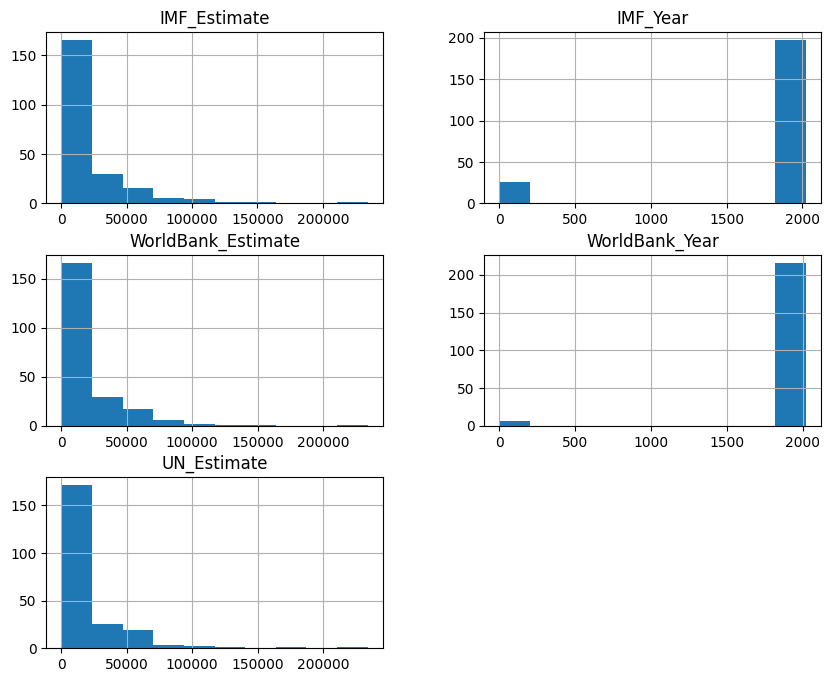

In [ ]:
df.hist(figsize=(10,8))
plt.show()

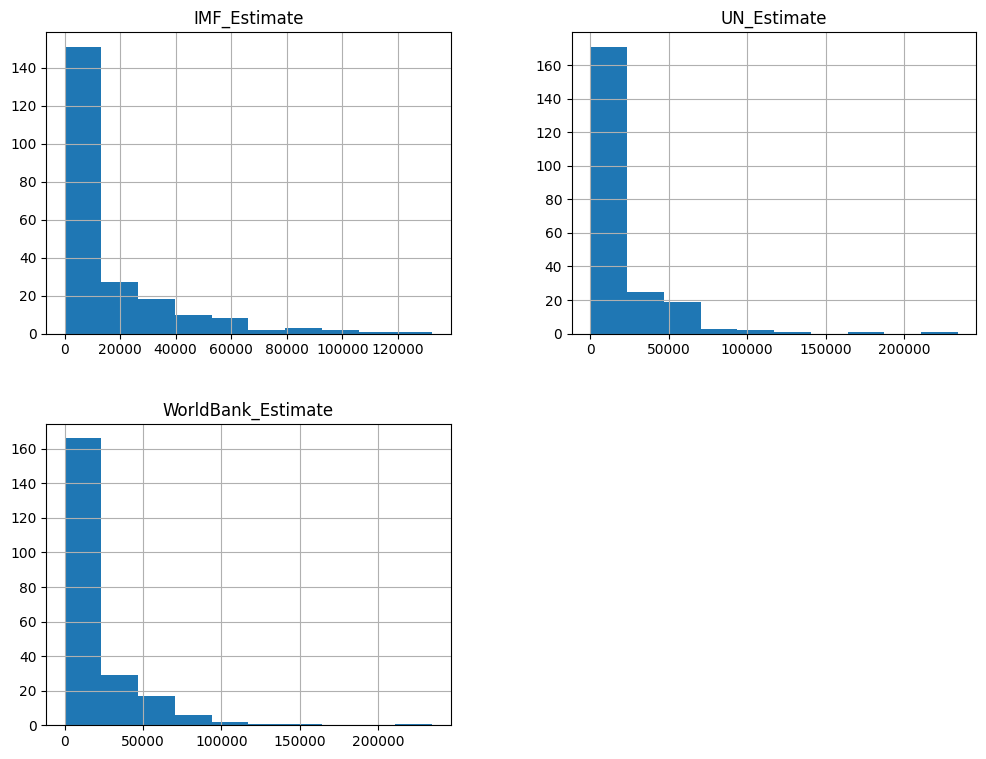

In [ ]:
df[["IMF_Estimate", "UN_Estimate", "WorldBank_Estimate"]].hist(figsize=(12,9))

plt.show()

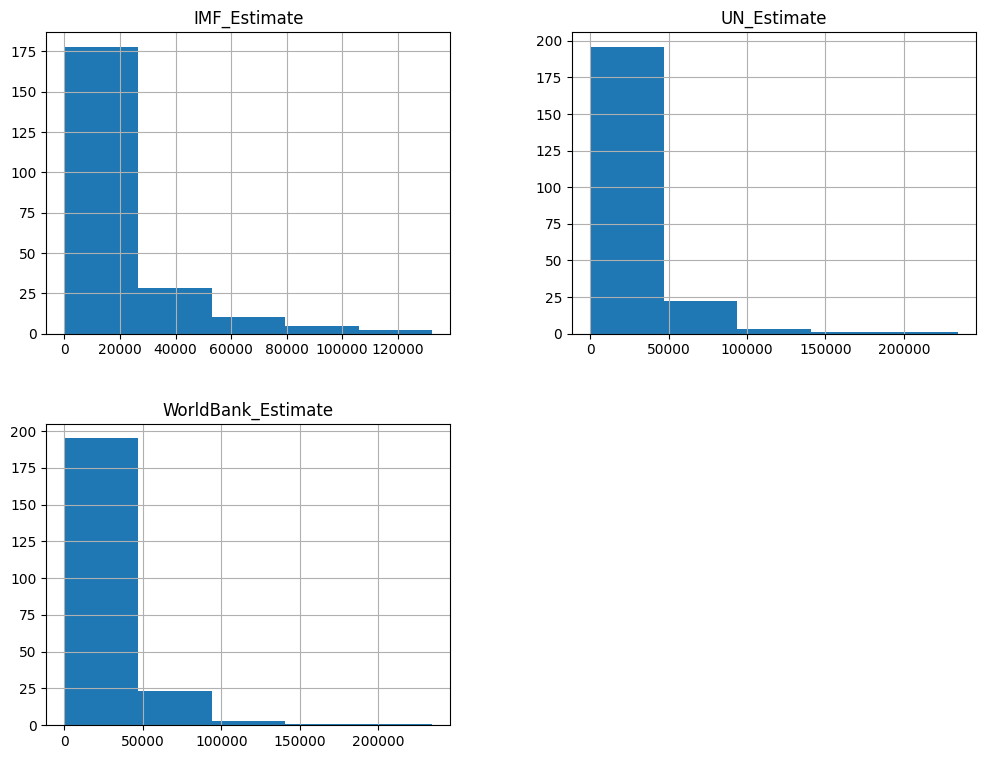

In [ ]:
df[["IMF_Estimate", "UN_Estimate", "WorldBank_Estimate"]].hist(bins=5, figsize=(12,9))

plt.show()

In [ ]:
df["WorldBank_Estimate"].agg(["min","max"])

,WorldBank_Estimate
min,0
max,234316


In [ ]:
234316/5
#1 bin size if bins=5

46863.2

In [ ]:
df[df["WorldBank_Estimate"]<=46863.2]["WorldBank_Estimate"].count()

np.int64(195)

In [ ]:
234316/10
#1 bin size if bins not given any number

23431.6

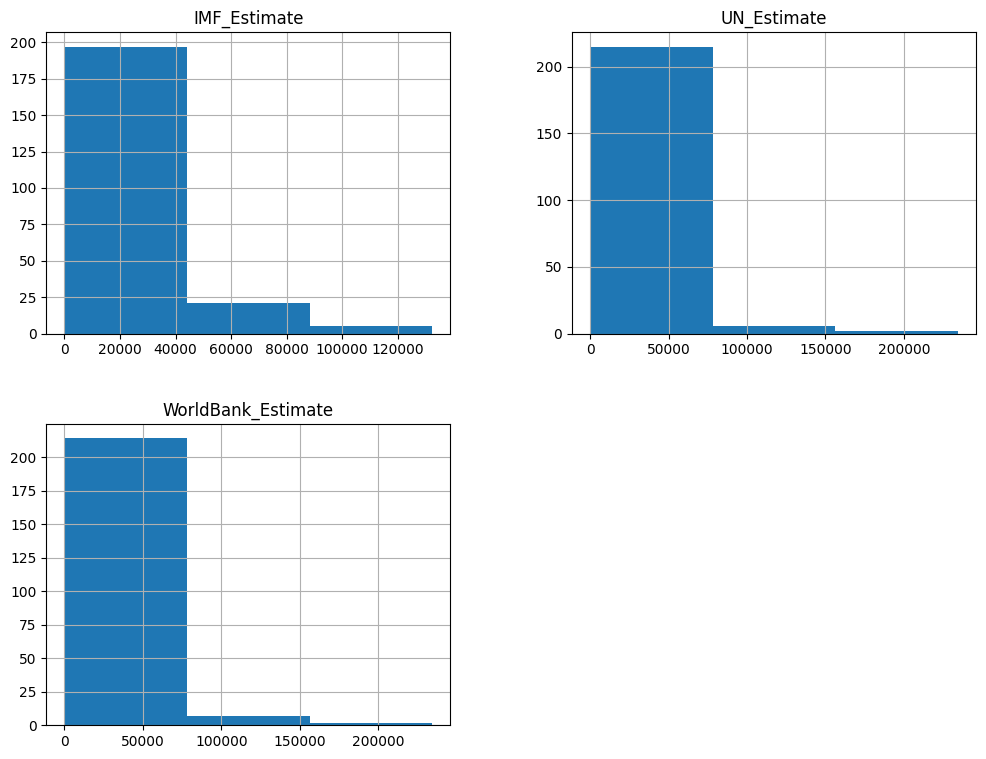

In [ ]:
df[["IMF_Estimate", "UN_Estimate", "WorldBank_Estimate"]].hist(bins=3, figsize=(12,9))

plt.show()

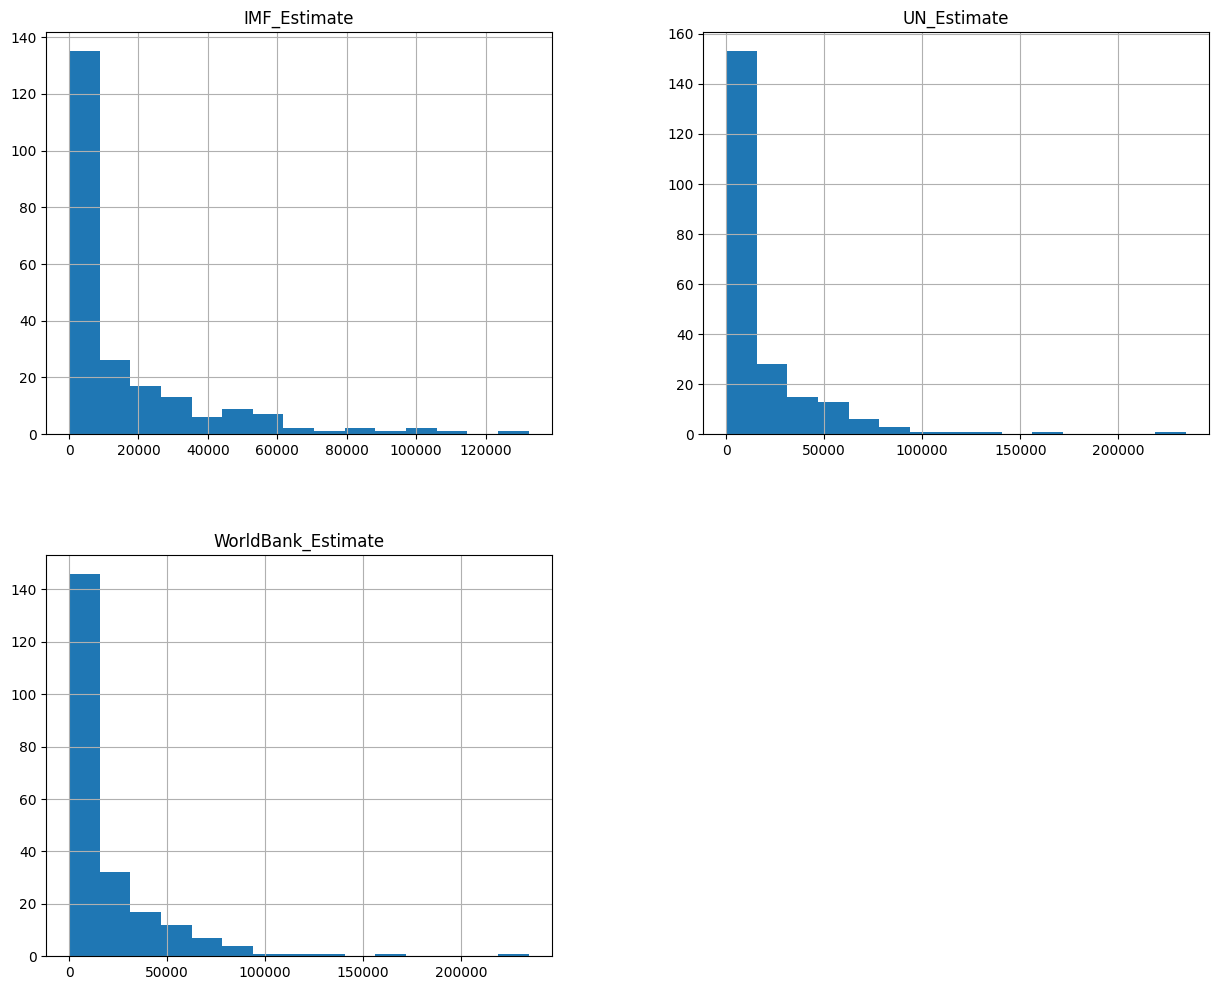

In [ ]:
df[["IMF_Estimate", "UN_Estimate", "WorldBank_Estimate"]].hist(bins=15, figsize=(15,12))

#23400/15 = 15300
plt.show()

### Correlation Heatmap

In [ ]:
df[["IMF_Estimate", "UN_Estimate", "WorldBank_Estimate"]].corr()

,IMF_Estimate,UN_Estimate,WorldBank_Estimate
IMF_Estimate,1.000000,0.626513,0.587988
UN_Estimate,0.626513,1.000000,0.930331
WorldBank_Estimate,0.587988,0.930331,1.000000


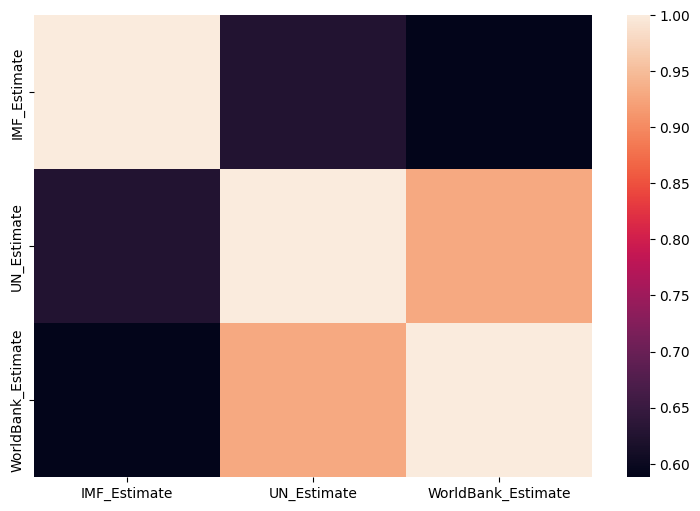

In [ ]:
corr = df[["IMF_Estimate", "UN_Estimate", "WorldBank_Estimate"]].corr()

plt.figure(figsize=(9,6))
sns.heatmap(corr)

plt.show()

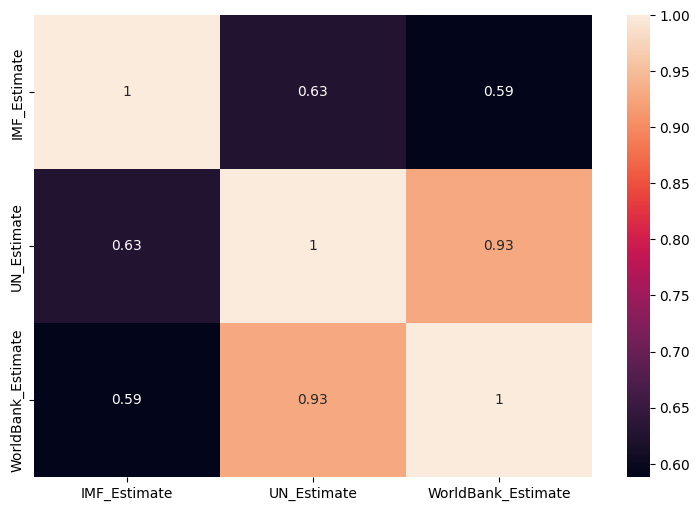

In [ ]:
corr = df[["IMF_Estimate", "UN_Estimate", "WorldBank_Estimate"]].corr()

plt.figure(figsize=(9,6))

sns.heatmap(corr, annot=True)

plt.show()

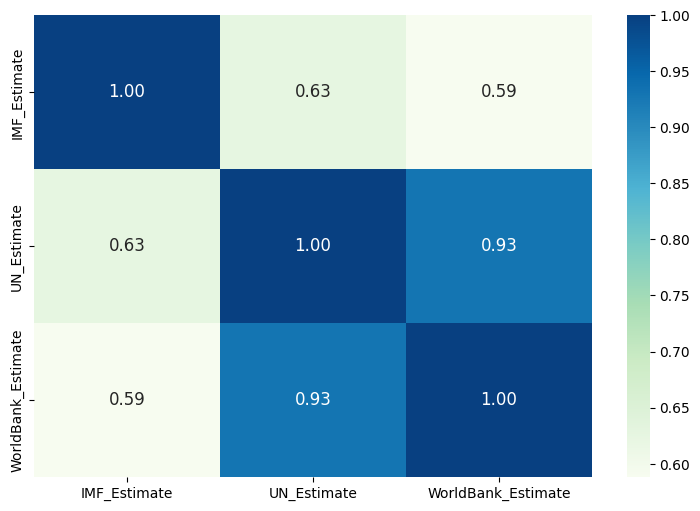

In [ ]:
corr = df[["IMF_Estimate", "UN_Estimate", "WorldBank_Estimate"]].corr()

plt.figure(figsize=(9,6))

sns.heatmap(corr, annot=True, fmt=".2f", cmap = 'GnBu', annot_kws={"size": 12})

plt.show()

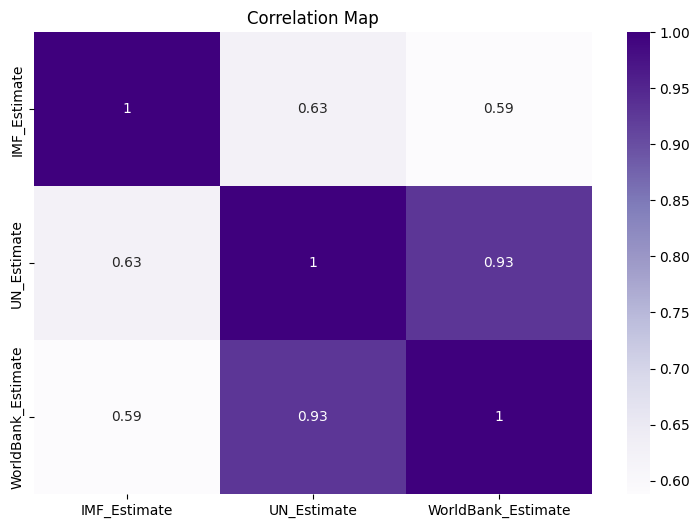

In [ ]:
corr = df[["IMF_Estimate", "UN_Estimate", "WorldBank_Estimate"]].corr()

plt.figure(figsize=(9,6))

sns.heatmap(corr, annot=True, cmap = 'Purples')

plt.title("Correlation Map")


plt.show()

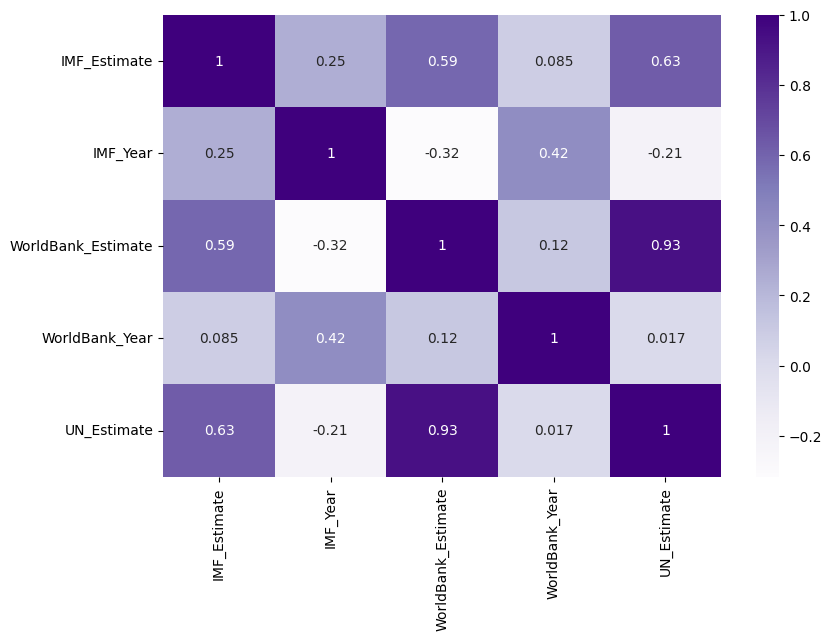

In [ ]:
corr = df.select_dtypes(include=[int, float]).corr()

plt.figure(figsize=(9,6))

sns.heatmap(corr, annot=True, cmap = 'Purples')

plt.show()

### Bar plot

In [ ]:
df.head()

,Country/Territory,UN_Region,IMF_Estimate,IMF_Year,WorldBank_Estimate,WorldBank_Year,UN_Estimate,UN_Year
1,Monaco,Europe,0,0,234316,2021,234317,2021
2,Liechtenstein,Europe,0,0,157755,2020,169260,2021
3,Luxembourg,Europe,132372,2023,133590,2021,133745,2021
4,Ireland,Europe,114581,2023,100172,2021,101109,2021
5,Bermuda,Americas,0,0,114090,2021,112653,2021


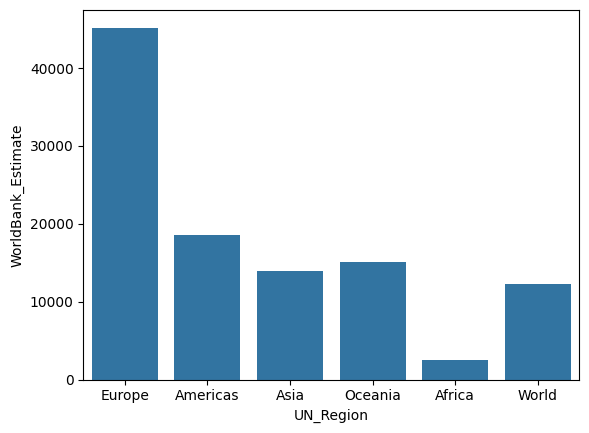

In [ ]:
sns.barplot(x="UN_Region", y="WorldBank_Estimate", data=df, errorbar=None)

plt.show()

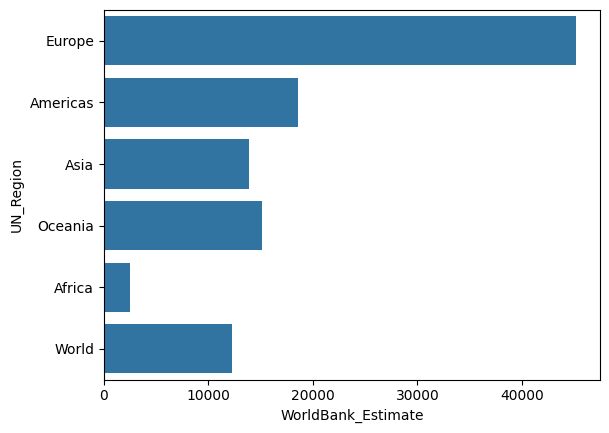

In [ ]:
sns.barplot(x="WorldBank_Estimate", y="UN_Region", data=df, errorbar=None)

plt.show()

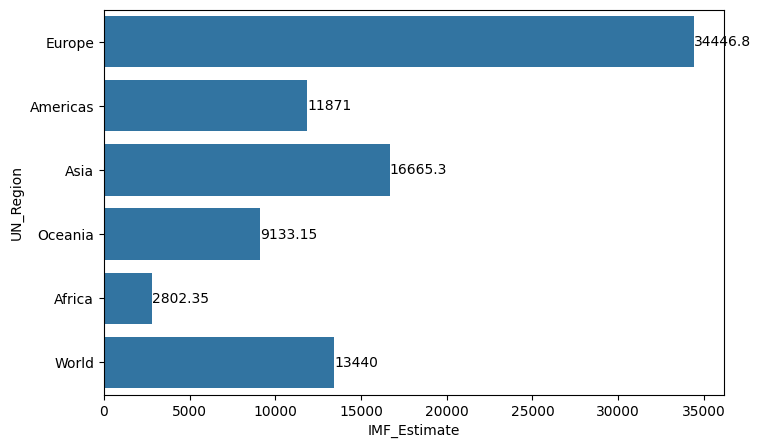

In [ ]:
fig = plt.figure(figsize = (8,5))

ax = sns.barplot(x = "IMF_Estimate",  y = "UN_Region",
data = df, errorbar = None)

ax.bar_label(ax.containers[0])

plt.show()

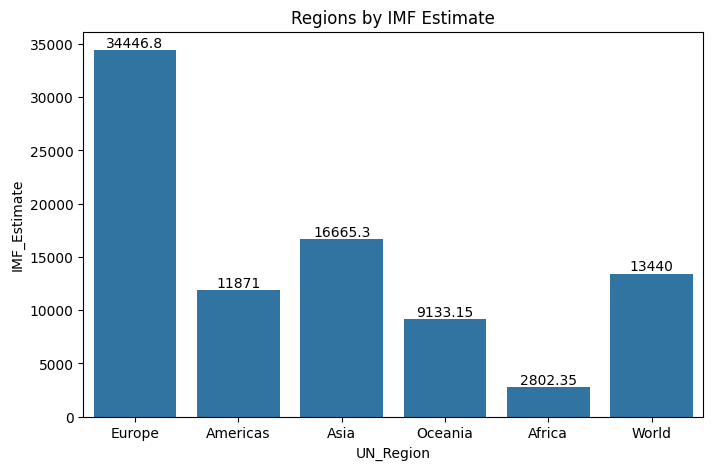

In [ ]:
fig = plt.figure(figsize = (8,5))
ax = sns.barplot(x = "UN_Region",  y = "IMF_Estimate",
                 data = df, errorbar = None)

ax.bar_label(ax.containers[0])


ax.set_title("Regions by IMF Estimate")
plt.show()

### Scatter Plot

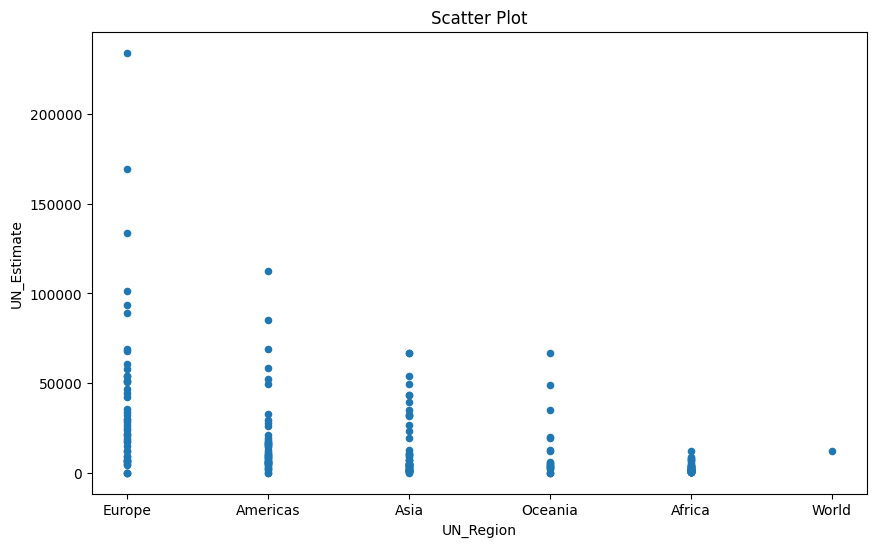

In [ ]:
df.plot(x='UN_Region', y='UN_Estimate', kind='scatter',
        figsize=(10,6),
        title="Scatter Plot")

plt.show()

### Boxplot and Outliers

![image.png](attachment:da6a7715-3b1c-4165-a2a9-4dc8ca096bd7.png)

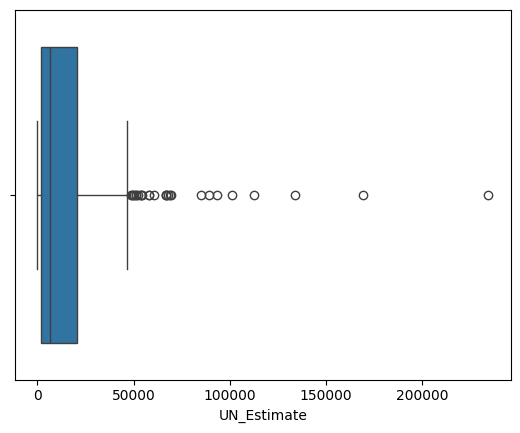

In [ ]:
sns.boxplot(x=df["UN_Estimate"])

plt.show()

In [ ]:
df[df["UN_Estimate"]>50000].head()

,Country/Territory,UN_Region,IMF_Estimate,IMF_Year,WorldBank_Estimate,WorldBank_Year,UN_Estimate,UN_Year
1,Monaco,Europe,0,0,234316,2021,234317,2021
2,Liechtenstein,Europe,0,0,157755,2020,169260,2021
3,Luxembourg,Europe,132372,2023,133590,2021,133745,2021
4,Ireland,Europe,114581,2023,100172,2021,101109,2021
5,Bermuda,Americas,0,0,114090,2021,112653,2021


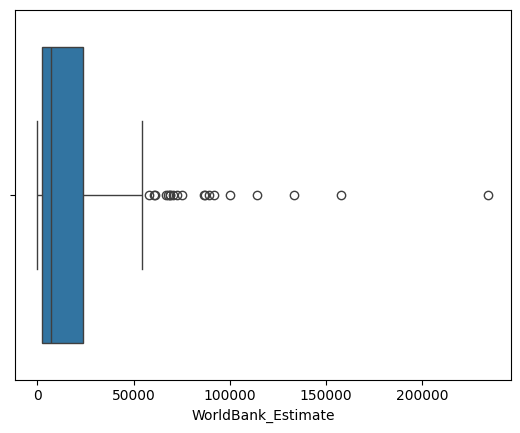

In [ ]:
sns.boxplot(x=df["WorldBank_Estimate"])

plt.show()

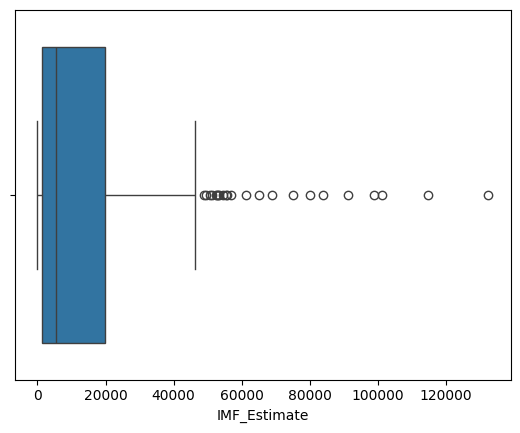

In [ ]:
sns.boxplot(x=df["IMF_Estimate"])

plt.show()

In [ ]:
df[df["UN_Estimate"]>100000]

,Country/Territory,UN_Region,IMF_Estimate,IMF_Year,WorldBank_Estimate,WorldBank_Year,UN_Estimate,UN_Year
1,Monaco,Europe,0,0,234316,2021,234317,2021
2,Liechtenstein,Europe,0,0,157755,2020,169260,2021
3,Luxembourg,Europe,132372,2023,133590,2021,133745,2021
4,Ireland,Europe,114581,2023,100172,2021,101109,2021
5,Bermuda,Americas,0,0,114090,2021,112653,2021


In [ ]:
df.UN_Estimate.mean()

np.float64(17767.304932735427)

In [ ]:
df.shape

(223, 8)

## Create another dataframe called data excluding  5 countries with highest UN estimate

In [ ]:
data = df[-(df["UN_Estimate"]>100000)]

In [ ]:
data.head()

,Country/Territory,UN_Region,IMF_Estimate,IMF_Year,WorldBank_Estimate,WorldBank_Year,UN_Estimate,UN_Year
6,Norway,Europe,101103,2023,89154,2021,89242,2021
7,Switzerland,Europe,98767,2023,91992,2021,93525,2021
8,Singapore,Asia,91100,2023,72794,2021,66822,2021
9,Isle of Man,Europe,0,0,87158,2019,0,0
10,Cayman Islands,Americas,0,0,86569,2021,85250,2021


In [ ]:
data.shape

(218, 8)

In [ ]:
data.UN_Estimate.mean()

np.float64(14729.47247706422)

In [ ]:
df.UN_Estimate.mean()

np.float64(17767.304932735427)

![image.png](attachment:image.png)

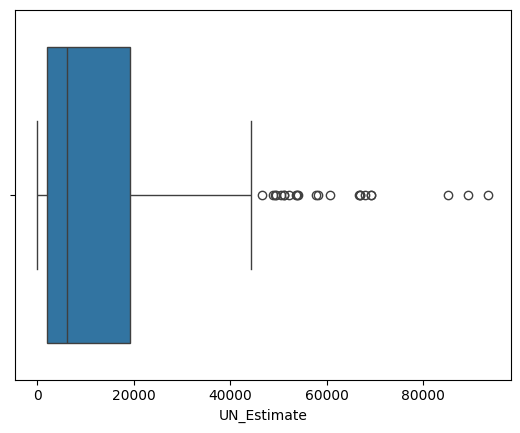

In [ ]:
sns.boxplot(x=data["UN_Estimate"])
plt.show()

## Removing outliers

![image.png](attachment:da6a7715-3b1c-4165-a2a9-4dc8ca096bd7.png)

![image.png](attachment:image.png)

In [ ]:
lower_q = df["UN_Estimate"].quantile(0.25)
lower_q

np.float64(2039.0)

In [ ]:
higher_q = df["UN_Estimate"].quantile(0.75)
higher_q

np.float64(20740.0)

In [ ]:
iqr = higher_q - lower_q
iqr

np.float64(18701.0)

In [ ]:
upper_boundary = higher_q + 1.5 * iqr
upper_boundary

np.float64(48791.5)

In [ ]:
lower_boundary = lower_q - 1.5 * iqr
lower_boundary

np.float64(-26012.5)

In [ ]:
df_filtered = df[(df["UN_Estimate"] < upper_boundary) & (df["UN_Estimate"] > lower_boundary)]

In [ ]:
df_filtered.head()

,Country/Territory,UN_Region,IMF_Estimate,IMF_Year,WorldBank_Estimate,WorldBank_Year,UN_Estimate,UN_Year
9,Isle of Man,Europe,0,0,87158,2019,0,0
14,Channel Islands,Europe,0,0,75153,2007,0,0
15,Faroe Islands,Europe,0,0,69010,2021,0,0
29,Macau,Asia,50571,2023,43874,2021,43555,2021
30,United Arab Emirates,Asia,49451,2023,44316,2021,43295,2021


In [ ]:
df_filtered.shape
# there were 223 rows - 196 = 27 outliers dropped

(196, 8)

In [ ]:
df_filtered.UN_Estimate.mean()

np.float64(9415.168367346938)

In [ ]:
df.UN_Estimate.mean()

np.float64(17767.304932735427)

In [ ]:
#how can we create a table with following
df_filtered.WorldBank_Estimate.mean()

np.float64(11096.647959183674)

In [ ]:
df.WorldBank_Estimate.mean()

np.float64(18927.417040358745)

In [ ]:
df_filtered.IMF_Estimate.mean()

np.float64(9784.326530612245)

In [ ]:
df.IMF_Estimate.mean()

np.float64(19935.053811659192)